## Autorzy:
## Błażej Kazior 252758
## Hubert Gryl 250962

# Challenge: maksymalny prąd w układzie rezystorów

**Zadanie:** układ składa się z trzech części połączonych szeregowo:
- R1 i R2 połączone równolegle,
- R3,
- R4 i R5 połączone równolegle.


Każdy rezystor ma swój dopuszczalny prąd. Trzeba wyznaczyć **największy prąd, jaki może przepłynąć przez cały układ**, i zapisać to jako problem liniowy.

| Rezystor | R1 | R2 | R3 | R4 | R5 |
|---|---|---|---|---|---|
| Rezystancja [Ω] | 8 | 6 | 4 | 10 | 8 |
| Prąd maksymalny [A] | 2 | 3 | 4 | 2 | 2 |


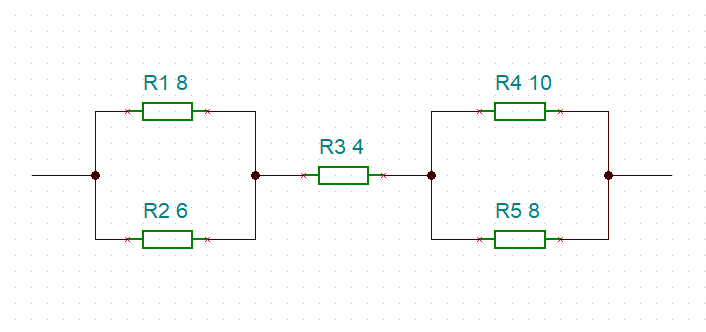

Rys. 1. Schemat układu z treści zadania

## 1. Zapis jako problem liniowy

**Zmienne decyzyjne:** prąd całkowity $I$ oraz prądy w rezystorach $I_1, \dots, I_5$ [A].

**Funkcja celu:** chcemy jak największego prądu w układzie:
$$\max \; I$$

**Ograniczenia:**
1. Prąd rozdziela się w węzłach (I prawo Kirchhoffa):
   $$I_1 + I_2 = I, \qquad I_3 = I, \qquad I_4 + I_5 = I$$
2. Na rezystorach połączonych równolegle jest to samo napięcie (prawo Ohma, $U = R \cdot I$):
   $$8 I_1 = 6 I_2, \qquad 10 I_4 = 8 I_5$$
3. Żaden rezystor nie może przekroczyć swojego prądu maksymalnego:
   $$0 \le I_1 \le 2,\quad 0 \le I_2 \le 3,\quad 0 \le I_3 \le 4,\quad 0 \le I_4 \le 2,\quad 0 \le I_5 \le 2$$


In [18]:
from scipy.optimize import linprog
import matplotlib.pyplot as plt

R = {1: 8, 2: 6, 3: 4, 4: 10, 5: 8}        # rezystancje [Ω]
I_max = {1: 2, 2: 3, 3: 4, 4: 2, 5: 2}     # prądy maksymalne [A]

In [19]:
def rozwiaz(R, I_max):
    # funkcja celu: max I  ->  min (-I)
    c = [-1, 0, 0, 0, 0, 0]

    # ograniczenia równościowe
    A_eq = [
        [-1, 1, 1, 0, 0, 0],            # I1 + I2 = I
        [-1, 0, 0, 1, 0, 0],            # I3 = I
        [-1, 0, 0, 0, 1, 1],            # I4 + I5 = I
        [0, R[1], -R[2], 0, 0, 0],      # R1*I1 = R2*I2
        [0, 0, 0, 0, R[4], -R[5]],      # R4*I4 = R5*I5
    ]
    b_eq = [0, 0, 0, 0, 0]

    # granice zmiennych: I >= 0 oraz 0 <= Ik <= Imax_k
    granice = [(0, None)] + [(0, I_max[k]) for k in R]

    wynik = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=granice)
    prady = {k: wynik.x[k] for k in R}
    return wynik.message, wynik.x[0], prady


status, I_calk, prady = rozwiaz(R, I_max)
print("Status:", status)
print(f"Maksymalny prąd układu: I = {I_calk:.3f} A\n")
for k in R:
    print(f"R{k}: I{k} = {prady[k]:.3f} A  (limit {I_max[k]} A, wykorzystanie {prady[k] / I_max[k] * 100:.0f}%)")

Status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Maksymalny prąd układu: I = 3.600 A

R1: I1 = 1.543 A  (limit 2 A, wykorzystanie 77%)
R2: I2 = 2.057 A  (limit 3 A, wykorzystanie 69%)
R3: I3 = 3.600 A  (limit 4 A, wykorzystanie 90%)
R4: I4 = 1.600 A  (limit 2 A, wykorzystanie 80%)
R5: I5 = 2.000 A  (limit 2 A, wykorzystanie 100%)


## 2. Wynik

Solver znalazł rozwiązanie optymalne: **maksymalny prąd układu wynosi 3,6 A**.

| Rezystor | Prąd [A] | Limit [A] | Wykorzystanie |
|---|---|---|---|
| R1 | 1,543 | 2 | 77% |
| R2 | 2,057 | 3 | 69% |
| R3 | 3,600 | 4 | 90% |
| R4 | 1,600 | 2 | 80% |
| **R5** | **2,000** | **2** | **100%** |

**Ograniczeniem jest rezystor R5.** Tylko on pracuje na swoim limicie. Większy prąd w układzie oznaczałby więcej niż 2 A w R5, a pozostałe rezystory mają jeszcze zapas.

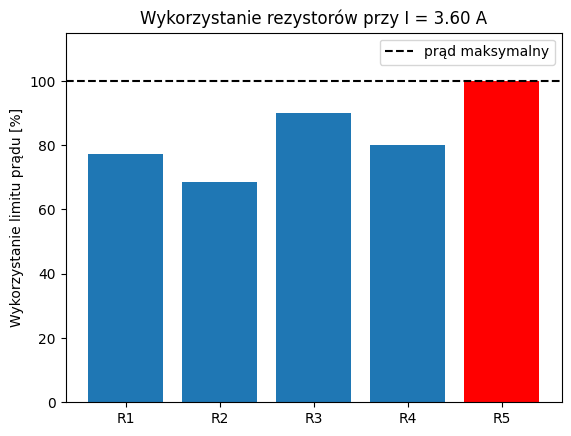

In [20]:
wykorzystanie = [prady[k] / I_max[k] * 100 for k in R]
nazwy = [f"R{k}" for k in R]
kolory = ["red" if w > 99.9 else "tab:blue" for w in wykorzystanie]

plt.bar(nazwy, wykorzystanie, color=kolory)
plt.axhline(100, color="black", linestyle="--", label="prąd maksymalny")
plt.ylabel("Wykorzystanie limitu prądu [%]")
plt.title(f"Wykorzystanie rezystorów przy I = {I_calk:.2f} A")
plt.ylim(0, 115)
plt.legend()
plt.show()

Rys. 2. Wykorzystanie dopuszczalnego prądu każdego rezystora przy maksymalnym prądzie układu

## 3. Sprawdzenie ręczne

W gałęzi równoległej prąd dzieli się odwrotnie proporcjonalnie do rezystancji, bo przez mniejszy opór płynie większy prąd. Dla każdego rezystora liczymy, przy jakim prądzie całkowitym $I$ osiągnie swój limit:

| Rezystor | Część prądu $I$ | Warunek | Największe $I$ |
|---|---|---|---|
| R1 | $\frac{R_2}{R_1+R_2} = \frac{6}{14} = 0{,}429$ | $0{,}429 I \le 2$ | 4,67 A |
| R2 | $\frac{R_1}{R_1+R_2} = \frac{8}{14} = 0{,}571$ | $0{,}571 I \le 3$ | 5,25 A |
| R3 | cały prąd | $I \le 4$ | 4,00 A |
| R4 | $\frac{R_5}{R_4+R_5} = \frac{8}{18} = 0{,}444$ | $0{,}444 I \le 2$ | 4,50 A |
| R5 | $\frac{R_4}{R_4+R_5} = \frac{10}{18} = 0{,}556$ | $0{,}556 I \le 2$ | **3,60 A** |

Najmniejsza z tych wartości to **3,6 A**, czyli tyle samo, ile dał solver. Napięcie zasilania przy tym prądzie:
$$R_z = \frac{8 \cdot 6}{8+6} + 4 + \frac{10 \cdot 8}{10+8} = 3{,}43 + 4 + 4{,}44 = 11{,}87\ \Omega, \qquad U = 3{,}6 \cdot 11{,}87 \approx 42{,}7\ \text{V}$$

## 4. Co jeśli zmienimy układ?

Prowadzący zwrócił uwagę, że w praktyce zmienia się prądy maksymalne lub rezystancje. Model LP pozwala to sprawdzić od razu, bez ponownego liczenia na kartce. Sprawdzamy dwie zmiany:
1. R5 o większym dopuszczalnym prądzie (3 A zamiast 2 A),
2. R4 i R5 o równych rezystancjach (po 9 Ω), żeby prąd dzielił się po równo.

In [21]:
warianty = {
    "bazowy": (R, I_max),
    "R5 z limitem 3 A": (R, {**I_max, 5: 3}),
    "R4 = R5 = 9 Ω": ({**R, 4: 9, 5: 9}, I_max),
}

for nazwa, (R_w, I_w) in warianty.items():
    status, I_w_calk, prady_w = rozwiaz(R_w, I_w)
    na_limicie = [f"R{k}" for k in R_w if abs(prady_w[k] - I_w[k]) < 1e-6]
    print(f"{nazwa}: I = {I_w_calk:.3f} A, na limicie: {', '.join(na_limicie)}")

bazowy: I = 3.600 A, na limicie: R5
R5 z limitem 3 A: I = 4.000 A, na limicie: R3
R4 = R5 = 9 Ω: I = 4.000 A, na limicie: R3, R4, R5


- **R5 z limitem 3 A:** prąd układu rośnie tylko do **4,0 A**, a nie dalej, bo teraz ogranicza R3. Przez R3 płynie cały prąd, a jego limit to 4 A. Wymiana samego R5 daje więc +0,4 A, a dalszą poprawę zablokuje R3.
- **R4 = R5 = 9 Ω:** prąd dzieli się po równo (po 50%), więc R4 i R5 osiągają limit 2 A razem przy **I = 4,0 A**. W tym samym momencie dochodzi do limitu R3. Lepsze dopasowanie rezystancji do limitów prądu daje tyle samo co wymiana R5 na mocniejszy.

## Wnioski

- Zadanie dało się zapisać jako problem liniowy, bo prawa Kirchhoffa i prawo Ohma przy stałych rezystancjach są liniowe. Solver znalazł maksymalny prąd **I = 3,6 A**, a sprawdzenie ręczne dało ten sam wynik.
- Układ ogranicza **R5**. Ma ten sam limit co R4 (2 A), ale mniejszą rezystancję, więc płynie przez niego większa część prądu (56%).
- Najsłabszy element nie zawsze jest tym o najmniejszym limicie. R1, R4 i R5 mają po 2 A, ale ograniczeniem jest tylko R5, bo liczy się limit w stosunku do prądu, który przez rezystor faktycznie płynie.
- Model pozwala szybko sprawdzić zmiany. Wymiana R5 albo dobranie rezystancji R4 i R5 podnosi prąd do 4 A. Dalej ogranicza już R3, przez który płynie cały prąd układu.